# Experimental C. elegans fluorescence restoration


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `celegans_wiener_deconvolution` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：observation (1, 310, 310) float32：Experimental processed Airyscan fluorescence export, intensity in a.u.; upstream loader removes three border pixels on each side.；psf (1, 13, 13) float32：Dimensionless unit-sum Gaussian effective PSF model, not measured calibration.。恢复目标：有效清晰荧光图，保留输入a.u.尺度。

获取模型：处理后Airyscan图在假定Gaussian PSF下满足扩展网格卷积加噪声。实际恢复算法：solvers.reconstruct显式FFT Wiener二次Laplacian正则闭式逆。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:5/57无生物真值；baseline是原始SWiener方法输出，PSF为假设模型。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：celegans_wiener_deconvolution.ipynb单元0：Experimental C. elegans fluorescence restoration；celegans_wiener_deconvolution.ipynb单元5：5. Results；celegans_wiener_deconvolution.ipynb单元7：Image and numerical comparisons；celegans_wiener_deconvolution.ipynb单元8有保存图；axes[0].set(xlabel='Column (pixel)', ylabel='Intensity (a.u.)', title='Central-row intensity profile')。图/比较代码位于单元8（从0计数）。代码单元4个，带execution_count的4个，保存PNG输出2幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：输入已是处理后Airyscan图；假定PSF下存在显式deconvolution inverse，但不能声称原始光子恢复或已验证真实光学PSF。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Recover an effective sharp fluorescence image from a processed Airyscan view of a C. elegans intestine. Blur suppresses spatial frequencies, and reversing it amplifies noise. The restoration is conditional on an assumed effective PSF because no independent sharp biological image or measured optical response is available.

We extract the associated framework's standard 2D Wiener demonstration and compare the observed image, an independently reproduced original result and a fresh local estimate. The SPITFIR(e) article (Scientific Reports 13, 1489, 2023, DOI 10.1038/s41598-022-26178-y) provides restoration context; its main SPITFIR(e) algorithm is not the selected method. The original input/Wiener comparison is retained with difference, profile and metric diagnostics.


## 2. Data

The real processed confocal Airyscan C. elegans intestine image is `sdeconv/data/celegans.tif` in https://github.com/sylvainprigent/sdeconv , revision `9b774221eb94fea23ae7a5ea6ad84b0b3632fce9` (version 1.0.4). Packaging follows the provider's `celegans()` loader exactly: crop `[3:-3,3:-3]` and cast to float32, giving 310 × 310 pixels without additional resampling, simulated blur or synthetic noise. Original sensor frames, physical sampling and instrument processing details are unavailable. The accompanying 13 × 13 Gaussian with sigma = 1.5 pixels is the demonstration's assumed effective PSF, not measured calibration; no independently sharp target is supplied. Repository BSD 3-Clause terms cover the selected code and data, with full attribution consolidated in `test/validation.md`.

| Key | Shape | Dtype | Description |
| --- | --- | --- | --- |
| observation | (1, 310, 310) | float32 | Experimental processed Airyscan fluorescence export, intensity in a.u.; upstream loader removes three border pixels on each side. |
| psf | (1, 13, 13) | float32 | Dimensionless unit-sum Gaussian effective PSF model, not measured calibration. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
| --- | --- | --- | --- |
| Modality | Confocal Airyscan processed export | none | Data provider's description; original instrument frames are unavailable. |
| Field size | 310 by 310 | pixel | Image after the provider's loader crop; no additional resampling. |
| Pixel pitch | 1 in both axes | pixel | Pixel-coordinate convention; physical pitch is unknown. |
| PSF standard deviation | 1.5 in both axes | pixel | Assumed effective Gaussian blur from the provider's example, not a measured optical width. |
| PSF support and center | 13 by 13; index (6, 6) | pixel | Unit-sum tabulated kernel. |
| Boundary extension | 13 pixels on each side, reflect excluding endpoint | pixel | Extended grid is 336 by 336; circular model on that grid, central crop for output. |
| Kernel origin | Move embedded center (168,168) to (0,0) | pixel | Embed kernel starting at (162,162) before circular convolution. |
| Frequency convention | Unnormalized forward DFT; inverse divided by grid size | none | Frequencies follow standard FFT ordering. |
| Noise parameters | Unknown | a.u. | Residual additive model; no known variance, photon gain or detector offset. |
| Physical sampling and optics | Not supplied | none | Do not infer micrometers, wavelength or numerical aperture. |

The 310 by 310 image and 13 by 13 effective PSF use the same pixel grid; the PSF integrates to one. Its status as an assumed model, rather than optical calibration, limits physical interpretation.


In [1]:
from pathlib import Path
import sys, time, json, subprocess
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
if not (ROOT / 'src').exists(): raise RuntimeError('Run from task root or notebooks directory')
sys.path.insert(0, str(ROOT))
from src.preprocessing import load_data, prepare
from src.solvers import reconstruct
from src.physics_model import transfer_function, apply_blur, laplacian
from src.visualization import compare, agreement
observation, psf = load_data(ROOT / 'data/raw_data.npz')
print('Observation:', observation.shape, 'PSF sum:', psf.sum(), 'units: arbitrary intensity / dimensionless kernel')

Observation: (310, 310) PSF sum: 1.0000000209104947 units: arbitrary intensity / dimensionless kernel


## 3. Physics

The unknown $x$ is an effective latent fluorescence intensity (a.u.), and the observation $y$ is a processed Airyscan export in the same units. For integer row/column index $r$ and dimensionless normalized PSF $h$:

$$
p(r)=(Hx)(r)+\epsilon(r),\qquad (Hx)(r)=\sum_s h(s)x(r-s),\qquad \sum_s h(s)=1.
$$

$p$ is the 336 × 336 reflection extension of the 310 × 310 observation. Reflection excludes endpoint pixels; convolution on the extended grid is circular. Rows increase downward and columns rightward. The effective PSF specified in Data supplies the convolution kernel. Unknown gain and noise variance preclude a calibrated Poisson count model.

The kernel is normalized and embedded at indices 162:175 in both axes; its center (168,168) is rolled to FFT origin (0,0). This avoids an unintended image translation. The FFT uses an unnormalized forward transform and inverse divided by 336². After inversion the requested central image removes 13 pixels per edge; no further alignment or rescaling occurs.


## 4. Method

On the extended grid, let $L$ be the positive five-point periodic Laplacian:

$$
(Lx)_{ij}=4x_{ij}-x_{i-1,j}-x_{i+1,j}-x_{i,j-1}-x_{i,j+1}.
$$

The Laplacian-regularized objective is $J(x)=\tfrac12\|Hx-p\|^2+\tfrac\beta2\|Lx\|^2$ with $\beta=0.005$, using unnormalized sums over all extended pixels. Stationarity gives $(H^*H+\beta L^*L)x=H^*p$. If $q$, $d$ and $P$ are the DFTs of the blur kernel, Laplacian impulse and reflected observation, respectively, the solution is

$$
X=\frac{\overline q P}{|q|^2+\beta|d|^2},\qquad x=\operatorname{Re}\operatorname{DFT}^{-1}(X).
$$

After evaluating this quotient, crop the 13-pixel reflected margin. This is a direct inverse with no initial iterate, learning rate, update loop or convergence tolerance. Signed ringing is retained without positivity clipping or intensity rescaling.

The blur DC response is 1 and the Laplacian DC response is 0, so total intensity is conserved on the full extended grid. The centered Laplacian impulse contributes a Fourier phase, but only its squared modulus enters the inverse; the independent spatial stencil therefore provides a separate normal-equation check.


## 5. Results

The following cell actively reconstructs the bound observation, writes the submission and evaluates the fresh pixels. The comparison groups remain observation, reproduced original Wiener and freshly computed local Wiener. No independently sharp biological truth is available.


In [2]:
started = time.perf_counter()
fresh = reconstruct(observation, psf)
runtime_seconds = time.perf_counter() - started
(ROOT / 'output').mkdir(exist_ok=True)
np.savez_compressed(ROOT / 'output/reconstruction.npz', reconstruction=fresh[None])
print(f'Fresh local reconstruction runtime: {runtime_seconds:.6f} seconds')
with np.load(ROOT / 'notebooks/reference_outputs/upstream.npz', allow_pickle=False) as data:
    upstream = data['reconstruction'][0]
measurements = {'reproduced_upstream_self': agreement(upstream, upstream),
                'fresh_local_vs_reproduced_upstream': agreement(fresh, upstream),
                'observation_vs_reproduced_upstream': agreement(observation, upstream)}
print(json.dumps(measurements, indent=2))
run = subprocess.run([sys.executable, str(ROOT/'evaluation/judge.py'), '--prediction', str(ROOT/'output/reconstruction.npz'), '--report', str(ROOT/'output/judge_report.json')], capture_output=True, text=True)
assert run.returncode == 0, run.stderr
print((ROOT/'output/judge_report.json').read_text())

Fresh local reconstruction runtime: 0.013198 seconds
{
  "reproduced_upstream_self": {
    "ncc": 1.0000000000000002,
    "nrmse": 0.0
  },
  "fresh_local_vs_reproduced_upstream": {
    "ncc": 0.9999999999999815,
    "nrmse": 4.899143052145996e-08
  },
  "observation_vs_reproduced_upstream": {
    "ncc": 0.9977186397247634,
    "nrmse": 0.017267840724207076
  }
}
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 0.9999999999999815,
    "nrmse": 4.899143052145996e-08
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 2e-06
    }
  },
  "errors": []
}



### Image and numerical comparisons

All first three panels share the observation's 1st to 99.5th percentile display limits. The difference has its own labeled intensity scale. These are display limits only; no array is clipped before comparison. Reproduced upstream denotes the actual original CPU run on these exact observations, not the archived TIFF demo result. Fresh local is computed in the preceding cell.


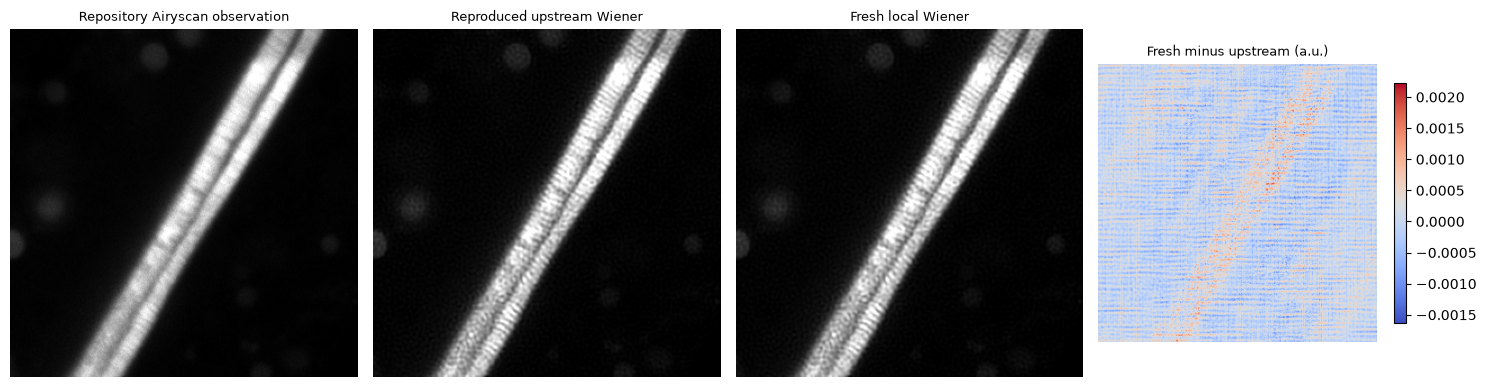

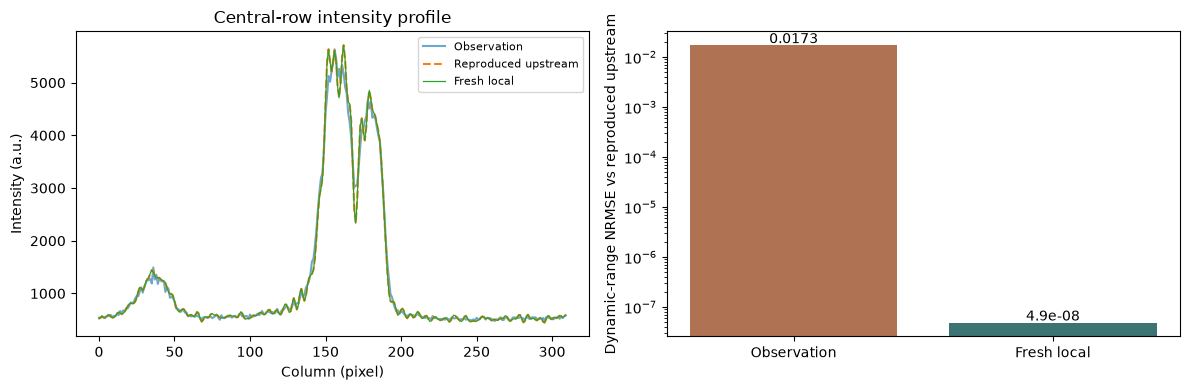

In [3]:
fig = compare(observation, upstream, fresh)
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
row = 155
axes[0].plot(observation[row], label='Observation', alpha=.65)
axes[0].plot(upstream[row], label='Reproduced upstream', linestyle='--')
axes[0].plot(fresh[row], label='Fresh local', linewidth=.9)
axes[0].set(xlabel='Column (pixel)', ylabel='Intensity (a.u.)', title='Central-row intensity profile')
axes[0].legend(fontsize=8)
names = ['Observation', 'Fresh local']
values = [measurements['observation_vs_reproduced_upstream']['nrmse'], measurements['fresh_local_vs_reproduced_upstream']['nrmse']]
axes[1].bar(names, values, color=['#af7354','#3c7373'])
axes[1].set(ylabel='Dynamic-range NRMSE vs reproduced upstream', yscale='log')
for i,v in enumerate(values): axes[1].text(i, v*1.1, f'{v:.3g}', ha='center')
fig.tight_layout(); plt.show()

### Independent mathematical check and interpretation

For full extended-grid $x$, verify $H^*(Hx-p)+ \beta L(Lx)=0$ using the conjugate blur operator and an independent spatial five-point Laplacian. Its residual and DC flux test are independent of visual agreement. Image-level forward residual need not vanish: regularization trades fidelity for conditioning, and the effective kernel is approximate. A cropped result cannot reproduce reflection margins, so stationarity is checked on the full extended solution.

NCC here is cosine similarity without mean subtraction. NRMSE is RMS error divided by reference maximum minus minimum. Both evaluate complete unaligned arrays. No phase or scale fit is applied.


In [4]:
padded, kernel = prepare(observation, psf)
otf = transfer_function(kernel)
full = reconstruct(observation, psf, return_full=True)
normal_residual = apply_blur(apply_blur(full, otf)-padded, otf, adjoint=True) + .005*laplacian(laplacian(full))
relative_normal_residual = np.linalg.norm(normal_residual)/np.linalg.norm(padded)
print('Relative normal equation residual:', relative_normal_residual)
print('Relative full-grid flux error:', abs(full.sum()-padded.sum())/abs(padded.sum()))
print('Relative forward observation residual:', np.linalg.norm(apply_blur(full,otf)-padded)/np.linalg.norm(padded))
assert relative_normal_residual < 1e-13
assert measurements['fresh_local_vs_reproduced_upstream']['nrmse'] < 2e-6

Relative normal equation residual: 2.7297660231328754e-16
Relative full-grid flux error: 0.0
Relative forward observation residual: 0.035350562061759946


## 6. Conclusion

The fresh float64 local FFT estimator reproduces the independent float32 upstream run and satisfies the regularized normal equation. The real processed image supplies useful structural content, but no independent biological ground truth or measured optical PSF is available. Detail enhancement and numerical agreement must therefore be interpreted as conditional restoration, with potential ringing and model mismatch. No historical paper score is substituted for fresh measurements.

The printed normal-equation residual, full-grid flux error and nonzero forward residual separate mathematical stationarity from fidelity to actual optics. The observation-versus-reference bar shows the identity submission differs from the specified estimator; it does not measure biological improvement against truth.
